In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import gc
import math

import matplotlib.pyplot as plt
import seaborn as sns
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from utils import get_opt, get_loaders, eval_ppl

In [2]:
DEV = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Load

## Model

In [3]:
model_name = "HuggingFaceTB/SmolLM2-1.7B"

model = get_opt(model_name)
model.eval()
model.to(DEV)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 2048)
    (layers): ModuleList(
      (0-23): 24 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (rotary_emb)

## Datasets

In [4]:
n_samples = 512
# n_samples = 256
# n_samples = 128

dataloader, testloader = get_loaders(
    "c4", nsamples=n_samples, seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (8597 > 8192). Running this sequence through the model will result in indexing errors


In [5]:
wiki_dataloader, wiki_testloader = get_loaders(
    'wikitext2', seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (2565857 > 8192). Running this sequence through the model will result in indexing errors


ts torch.Size([1, 2565857])


In [6]:
base_ppl = eval_ppl(model, testloader, device=DEV)
base_loss = float(np.log(base_ppl))
base_ppl, base_loss

(11.781546592712402, 2.4665344593096408)

# Utils

In [7]:
def visualize_dist(gate_store, ax=None):
    flat = torch.cat([t.reshape(-1) for t in gate_store])
    values = flat.float().detach().cpu().numpy()
    num_unique = len(np.unique(values))
    bins = min(100, num_unique)
    if ax is None: 
        plt.figure(figsize=(6, 3))
        plt.hist(values, bins=bins)
        plt.xlabel("Value")
        plt.ylabel("Count")
        plt.title("Distribution of decisions")
        plt.show()
    else:
        ax.hist(values, bins=bins)
        ax.set_xlabel("Value")
        ax.set_ylabel("Count")
        ax.set_title("Distribution of decisions")

def visualize_gate_heatmap(gate_store):
    """
    gate_store: list of tensors [1, T, 1], one per layer
    """

    # Shape: [L, T]
    mat = torch.stack([g.squeeze() for g in gate_store], dim=0)
    mat = mat.detach().cpu().float().numpy()

    plt.figure(figsize=(12, 6))
    plt.imshow(mat, aspect="auto")
    plt.colorbar(label="Gate value")
    plt.xlabel("Token index")
    plt.ylabel("Layer index")
    plt.title("Gate heatmap (layers × tokens)")
    plt.show()


# Architecture

In [8]:
class TokenGate(nn.Module):
    def __init__(self, d_model, noise_scale=0.0, tau=1.0):
        super().__init__()
        self.proj = nn.Linear(d_model, 1, dtype=torch.float32)
        self.noise_scale = noise_scale
        self.tau = tau

    def forward(self, h):
        logits = self.proj(h.to(torch.float32))              # [B, T, 1]

        if self.training and self.noise_scale > 0:
            u = torch.rand_like(logits).clamp(1e-6, 1-1e-6)
            noise = torch.log(u) - torch.log(1-u)        # logistic noise
            logits = logits + self.noise_scale * noise
        
        gate = torch.sigmoid(logits / self.tau)
        return gate


In [9]:
class GatedMLP(nn.Module):
    def __init__(self, mlp: nn.Module, d_model: int, gate_store: list,  noise_scale=0.0, tau=1.0):
        super().__init__()
        self.mlp = mlp
        self.gate = TokenGate(d_model, noise_scale=noise_scale, tau=tau)
        self.gate_store = gate_store      # to collect gates for loss
        self.active_gate = True

    def forward(self, h):
        if not self.active_gate:
            return self.mlp(h)
            
        g = self.gate(h)                  # [B, T, 1]
        self.gate_store.append(g)

        if self.training:            
            return g.to(h.dtype) * self.mlp(h)        # Standard continuous gating
        
        # --- Inference / Eval Mode Logic ---
        g_binary = (g > 0.5).to(h.dtype)
        g_flat = g_binary.view(-1)        # [B*T]
        h_flat = h.view(-1, h.size(-1))   # [B*T, D]
        active_indices = torch.where(g_flat > 0.5)[0]

        out_flat = torch.zeros_like(h_flat)
        if active_indices.numel() > 0:
            # only compute MLP for active tokens
            h_active = h_flat[active_indices]
            out_active = self.mlp(h_active)
            
            out_flat[active_indices] = out_active

        return out_flat.view(h.shape)

In [10]:
def deactivate_gates(model):
    for layer in model.model.layers:
        layer.mlp.active_gate = False 

def activate_gates(model):
    for layer in model.model.layers:
        layer.mlp.active_gate = True 

def add_gates(model, gate_store, noise_scale=0.0, tau=1.0):
    for layer in model.model.layers:
        d_model = layer.mlp.gate_proj.in_features
        layer.mlp = GatedMLP(layer.mlp, d_model, gate_store, noise_scale=noise_scale, tau=tau)

def set_noise(model, noise_scale=0.0):
    for layer in model.model.layers:
        layer.mlp.gate.noise_scale = noise_scale

def set_tau(model, tau=1.0):
    for layer in model.model.layers:
        layer.mlp.gate.tau = tau

In [11]:
def freeze_all_but_gates(model):
    for p in model.parameters():
        p.requires_grad = False
    for layer in model.model.layers:
        for p in layer.mlp.gate.parameters():   # TokenGate parameters
            p.requires_grad = True

def get_gate_params(model):
    weight_params = []
    bias_params = []
    for layer in model.model.layers:
        bias_params.append(layer.mlp.gate.proj.bias)
        weight_params.append(layer.mlp.gate.proj.weight)
    return weight_params, bias_params

def set_init_gate_weights(model, init_skip=0.3, w_std=1e-1):
    init_logit = math.log((1-init_skip) / init_skip)

    for layer in model.model.layers:
        gate = layer.mlp.gate.proj
        gate.bias.data.fill_(init_logit)
        gate.weight.data.normal_(0.0, w_std)
        

In [12]:
def kl_loss(student_logits, teacher_logits, T=1.0):
    # apply temperature
    student_log_probs = F.log_softmax(student_logits / T, dim=-1)
    teacher_probs = F.softmax(teacher_logits / T, dim=-1)

    loss = F.kl_div(
        student_log_probs,
        teacher_probs,
        reduction='batchmean'
    ) * (T ** 2)
    loss = loss / student_logits.size(1)  # divide by seq_len
    return loss

In [13]:
def gated_loss(lm_loss, gate_store,
               target_skip=0.3, lambda_ratio=1.0, lambda_bin=1.0):
    """
    lm_loss: scalar tensor
    gate_store: list of tensors [B, T, 1] (keep gates)
    """    
    # concatenate all gates -> [B*T*L]
    g = torch.cat([gi.reshape(-1) for gi in gate_store], dim=0)
    skip_ratio = (1.0 - g).mean()
    g_hard = torch.round(g.detach())
    skip_ratio_hard = (1.0 - g_hard).mean()

    # ratio loss (keep skip near target)
    ratio_loss = (skip_ratio - target_skip) ** 2

    # binarization loss (push gates to 0 or 1)
    bin_loss = (g * (1.0 - g)).mean()

    total_loss = lm_loss + lambda_ratio * ratio_loss + lambda_bin * bin_loss

    return total_loss, {
        "skip_ratio": skip_ratio,
        "skip_ratio_hard": skip_ratio_hard,
        "ratio_loss": ratio_loss.detach(),
        "bin_loss": bin_loss.detach(),
    }


In [14]:
def train_gates(model, dataloader, gate_store, stats, device="cuda",
                epochs=1, lrw=1e-4, lrb=1e-2,
                target_skip=0.30, lambda_ratio=1.0, lambda_bin=1.0,
                sigma_max=1, sigma_limit=0.7, tau_min=0.4, tau_limit=0.5,
                grad_accum_steps=1, max_grad_norm=1.0,
                verbose=False, eval_val_ppl=True, log_every=50):
    
    T = epochs * len(dataloader)

    # optimizer on gate params only
    weight_params, bias_params = get_gate_params(model)

    optimizer = torch.optim.AdamW([
        {"params": weight_params, "lr": lrw}, {"params": bias_params, "lr": lrb}
    ])
    
    scheduler = torch.optim.lr_scheduler.LinearLR(
        optimizer, start_factor=1.0, end_factor=0.001, total_iters=T
    )
    
    global_step = 0
    for epoch in range(epochs):
        for step, batch in enumerate(dataloader):
            global_step += 1
            gate_store.clear()

            input_ids, labels = batch
            batch = {"input_ids": input_ids.to(device), "labels": labels.to(device)}

            ##
            t = global_step / (T - 1)          # goes 0 -> 1
            
            tau   = 1.0 - (1.0 - tau_min) * min(1.0, t / tau_limit)    # 1 -> tau_min by (tau_limit*100) % of training
            sigma = sigma_max * (1.0 - min(1.0, t / sigma_limit))   # sigma_max -> 0 by (sigma_limit*100) % of training

            set_tau(model, tau)
            set_noise(model, sigma)
                        
            ##
            outputs = model(**batch)
            ppl = torch.exp(outputs.loss.detach()).item()
            # get original dense model outputs to calculate KL divergence
            with torch.no_grad():
                deactivate_gates(model)
                outputs_dense = model(**batch)
                activate_gates(model)
            
            lm_loss = kl_loss(outputs.logits, outputs_dense.logits)
            loss, loss_info = gated_loss(lm_loss, gate_store, lambda_ratio=lambda_ratio, lambda_bin=lambda_bin, target_skip=target_skip)
            loss = loss / grad_accum_steps
            loss.backward()

            if global_step % grad_accum_steps == 0:
                if max_grad_norm is not None:
                    torch.nn.utils.clip_grad_norm_(weight_params, max_grad_norm)
                    torch.nn.utils.clip_grad_norm_(bias_params, max_grad_norm)
                optimizer.step()
                optimizer.zero_grad(set_to_none=True)
                scheduler.step()

            # logging
            if (global_step == 1) or (global_step % log_every == 0):
                with torch.no_grad():
                    if verbose: visualize_dist(gate_store)
                    if eval_val_ppl:
                        model.eval()
                        val_ppl = eval_ppl(model, testloader, device=DEV)
                        model.train()
                    else: 
                        val_ppl = 0
                    lr = optimizer.param_groups[0]["lr"]
                    total_loss = lm_loss + lambda_ratio*loss_info['ratio_loss'] + lambda_bin*loss_info['bin_loss']
                    if verbose:
                        print(
                            f"{global_step:3} lr {lr:.1e} | "
                            # f"tau {tau:.2f} sigma {sigma:.2f} | "
                            f"ppl={ppl:6.2f} | val_ppl={val_ppl:6.2f} | "
                            f"skip_ratio={loss_info['skip_ratio'].item():.2f} | "
                            f"skip_ratio_h={loss_info['skip_ratio_hard'].item():.2f} | "
                            f"ratio_loss={(lambda_ratio*loss_info['ratio_loss']).item():.2f} | "
                            f"bin_loss={(lambda_bin*loss_info['bin_loss']).item():.2f} | "
                            f"kl_div={lm_loss.item():.2f} | "
                            f"total_loss={total_loss.item():.2f}"
                        )
                    stats['ppl'].append(ppl)
                    stats['val_ppl'].append(val_ppl)
                    stats['kl_div'].append(lm_loss.detach().cpu().item())
                    stats['skip_ratio'].append(loss_info['skip_ratio'].item())
                    stats['ratio_loss'].append((lambda_ratio*loss_info['ratio_loss']).item())
                    stats['bin_loss'].append((lambda_bin*loss_info['bin_loss']).item())
                    stats['total_loss'].append(total_loss.item())

    return model, stats

# Training

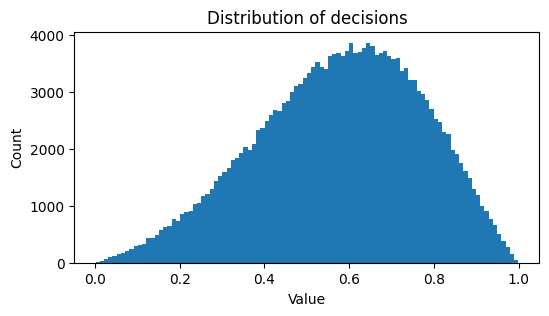

  1 lr 9.9e-03 | ppl=234.15 | val_ppl=  0.00 | skip_ratio=0.42 | skip_ratio_h=0.34 | ratio_loss=0.05 | bin_loss=0.21 | kl_div=3.20 | total_loss=3.46


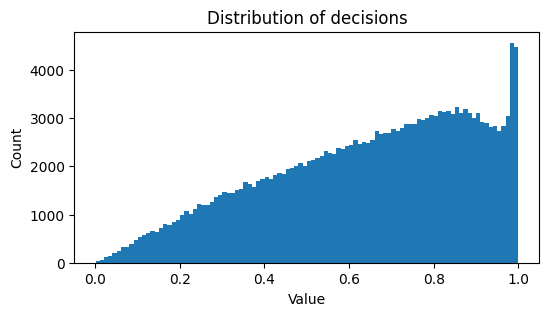

  8 lr 9.4e-03 | ppl=159.28 | val_ppl=  0.00 | skip_ratio=0.36 | skip_ratio_h=0.28 | ratio_loss=0.19 | bin_loss=0.17 | kl_div=0.57 | total_loss=0.94


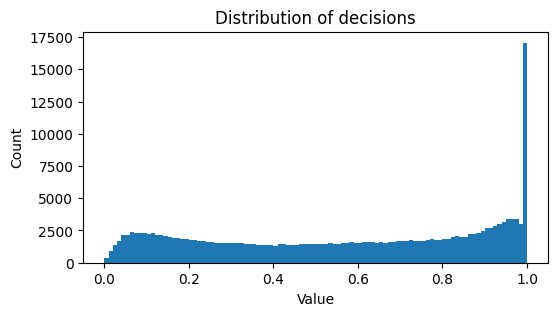

 16 lr 8.8e-03 | ppl=  8.43 | val_ppl=  0.00 | skip_ratio=0.43 | skip_ratio_h=0.42 | ratio_loss=0.09 | bin_loss=0.14 | kl_div=0.96 | total_loss=1.20


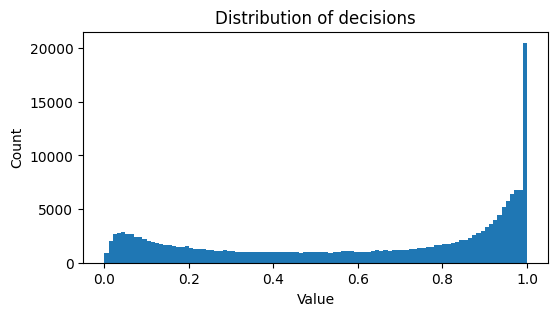

 24 lr 8.1e-03 | ppl=  1.18 | val_ppl=  0.00 | skip_ratio=0.38 | skip_ratio_h=0.37 | ratio_loss=0.03 | bin_loss=0.12 | kl_div=0.70 | total_loss=0.84


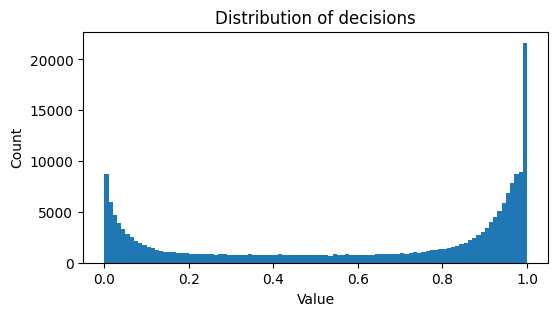

 32 lr 7.5e-03 | ppl=  1.13 | val_ppl=  0.00 | skip_ratio=0.39 | skip_ratio_h=0.37 | ratio_loss=0.02 | bin_loss=0.09 | kl_div=0.57 | total_loss=0.68


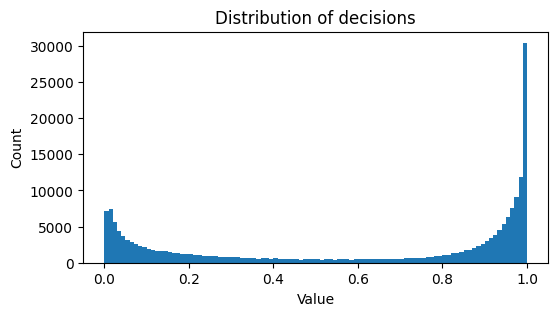

 40 lr 6.9e-03 | ppl=  1.01 | val_ppl=  0.00 | skip_ratio=0.39 | skip_ratio_h=0.39 | ratio_loss=0.00 | bin_loss=0.08 | kl_div=0.99 | total_loss=1.07


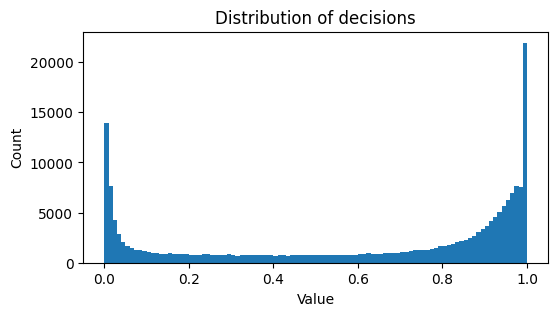

 48 lr 6.3e-03 | ppl=  2.59 | val_ppl=  0.00 | skip_ratio=0.38 | skip_ratio_h=0.36 | ratio_loss=0.03 | bin_loss=0.10 | kl_div=0.60 | total_loss=0.73


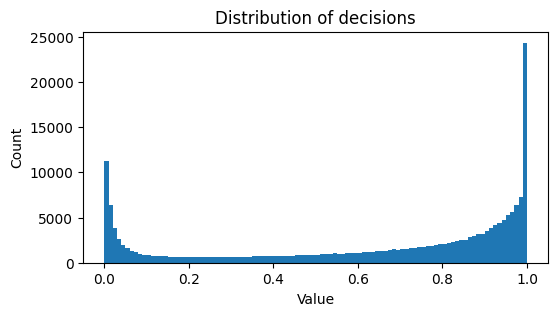

 56 lr 5.6e-03 | ppl=  9.31 | val_ppl=  0.00 | skip_ratio=0.36 | skip_ratio_h=0.31 | ratio_loss=0.18 | bin_loss=0.10 | kl_div=0.55 | total_loss=0.83


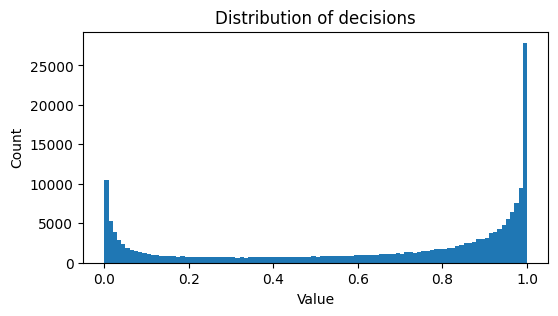

 64 lr 5.0e-03 | ppl=  7.78 | val_ppl=  0.00 | skip_ratio=0.35 | skip_ratio_h=0.32 | ratio_loss=0.21 | bin_loss=0.10 | kl_div=0.82 | total_loss=1.13


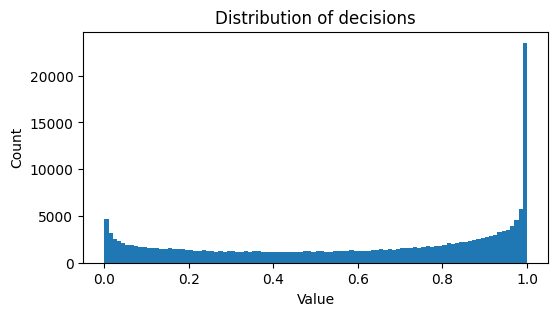

 72 lr 4.4e-03 | ppl= 46.29 | val_ppl=  0.00 | skip_ratio=0.40 | skip_ratio_h=0.38 | ratio_loss=0.00 | bin_loss=0.12 | kl_div=0.76 | total_loss=0.89


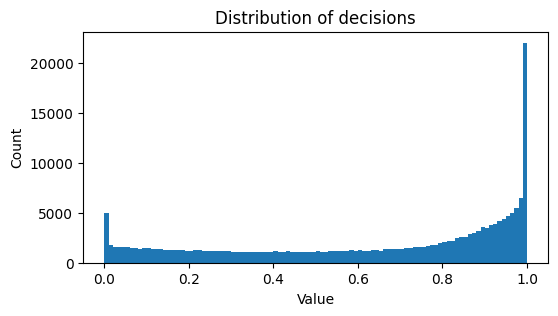

 80 lr 3.8e-03 | ppl= 16.81 | val_ppl=  0.00 | skip_ratio=0.36 | skip_ratio_h=0.34 | ratio_loss=0.14 | bin_loss=0.12 | kl_div=0.54 | total_loss=0.80


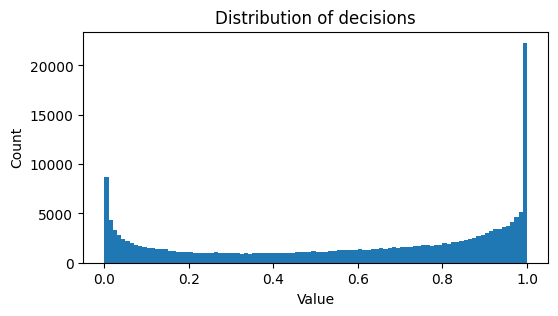

 88 lr 3.1e-03 | ppl= 14.36 | val_ppl=  0.00 | skip_ratio=0.41 | skip_ratio_h=0.37 | ratio_loss=0.00 | bin_loss=0.12 | kl_div=0.63 | total_loss=0.75


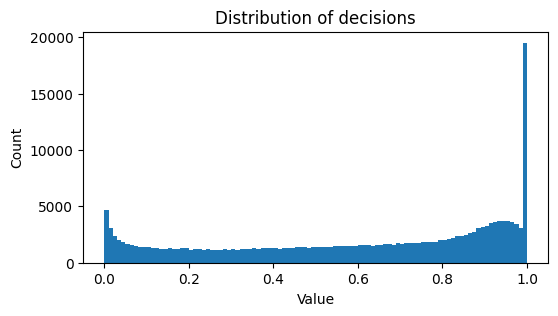

 96 lr 2.5e-03 | ppl=  1.28 | val_ppl=  0.00 | skip_ratio=0.40 | skip_ratio_h=0.36 | ratio_loss=0.00 | bin_loss=0.13 | kl_div=0.58 | total_loss=0.72


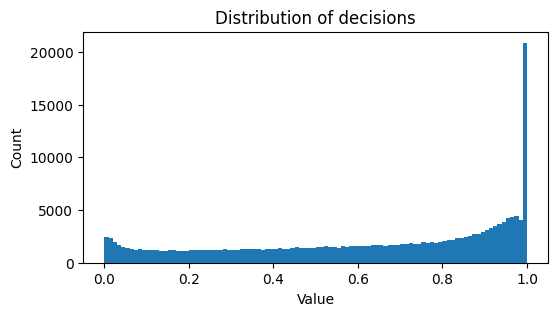

104 lr 1.9e-03 | ppl=  4.62 | val_ppl=  0.00 | skip_ratio=0.37 | skip_ratio_h=0.34 | ratio_loss=0.08 | bin_loss=0.13 | kl_div=0.47 | total_loss=0.69


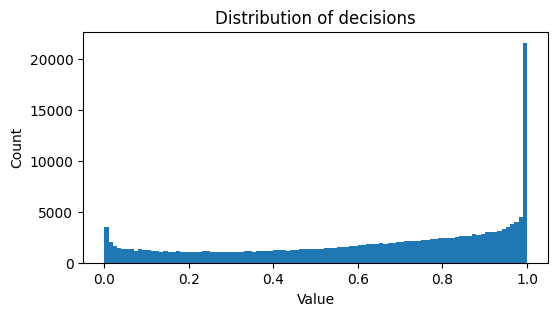

112 lr 1.3e-03 | ppl=  5.76 | val_ppl=  0.00 | skip_ratio=0.36 | skip_ratio_h=0.32 | ratio_loss=0.13 | bin_loss=0.13 | kl_div=0.48 | total_loss=0.74


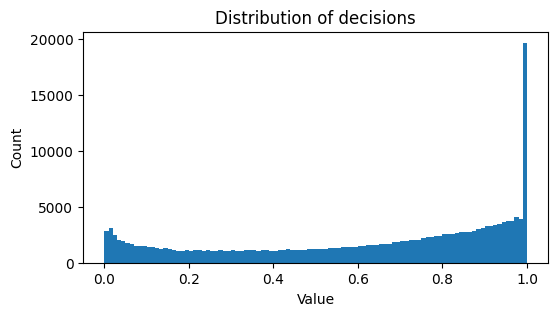

120 lr 6.3e-04 | ppl=  1.13 | val_ppl=  0.00 | skip_ratio=0.38 | skip_ratio_h=0.33 | ratio_loss=0.05 | bin_loss=0.13 | kl_div=0.49 | total_loss=0.67


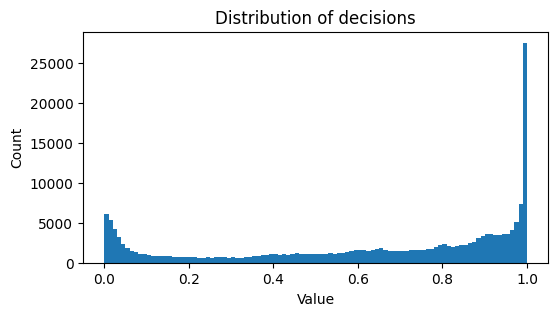

128 lr 1.0e-05 | ppl=  1.20 | val_ppl=  0.00 | skip_ratio=0.36 | skip_ratio_h=0.31 | ratio_loss=0.16 | bin_loss=0.11 | kl_div=0.42 | total_loss=0.70


In [37]:
stats = {'ppl': [], 'val_ppl': [], 'kl_div': [], 'skip_ratio': [], 'ratio_loss': [], 'bin_loss': [], 'total_loss': []}

model = get_opt(model_name)
gate_store = []
add_gates(model, gate_store=gate_store)
model.to(DEV)
model.train()

set_init_gate_weights(model, init_skip=0.4, w_std=1e-1)
freeze_all_but_gates(model)

model, stats = train_gates(
    model=model,
    dataloader=dataloader,
    gate_store=gate_store,
    stats=stats,
    device=DEV,
    epochs=1,
    lrb=1, lrw=1e-2,
    sigma_max=0.5, sigma_limit=0.7, tau_min=0.4, tau_limit=0.5,
    target_skip=0.40,
    lambda_ratio=1e2,
    lambda_bin=1,
    grad_accum_steps=1,
    log_every=8,
    verbose=True,
    eval_val_ppl=False
)
# model.eval();

## Training stats

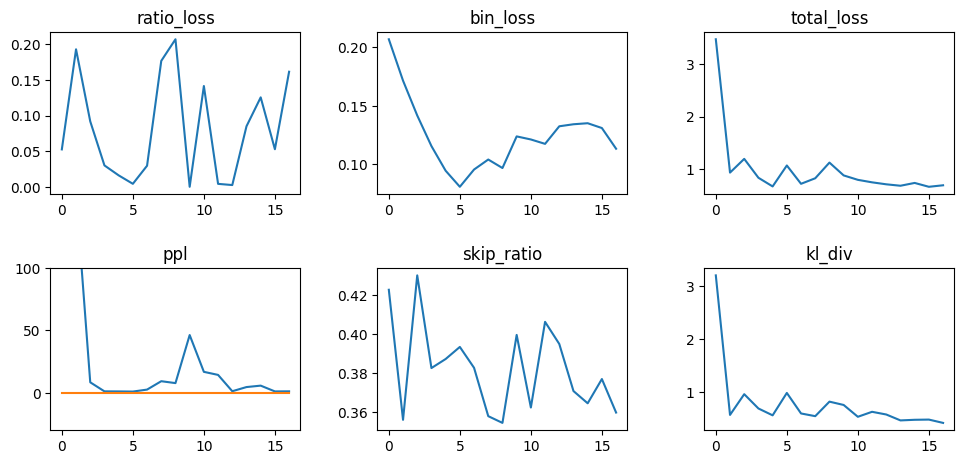

In [38]:
fig, ax = plt.subplots(2, 3, figsize=(10, 5))
for i, x in enumerate(['ratio_loss', 'bin_loss', 'total_loss', 'ppl', 'skip_ratio', 'kl_div']): # ,'distribution']):
    r, c = divmod(i, 3)
    if x == 'distribution':
        flat = torch.cat([t.reshape(-1) for t in gate_store[-24:]])
        values = flat.float().detach().cpu().numpy()
        ax[r, c].hist(values, bins=100)
        ax[r, c].set_xlabel("Value")
        ax[r, c].set_ylabel("Count")
        ax[r, c].set_title(x)
        continue
    ax[r, c].plot(stats[x])
    ax[r, c].set_title(x)
    if x == 'ppl': 
        ax[r, c].plot(stats['val_ppl'])
        if (max(stats['ppl']) > 1e2) or (max(stats['val_ppl']) > 1e2):
            ax[r, c].set_ylim((-30, 100))
fig.tight_layout(pad=2)

## Gated Model Evaluation

In [39]:
gate_store.clear()
model.eval()
eval_ppl(model, wiki_testloader, device=DEV)

16.644466400146484

In [40]:
# skip ratio
# torch.Tensor([x.mean() for x in gate_store]).mean()
1-torch.Tensor([x.mean() for x in gate_store[-24:]]).mean().item(), 1-torch.Tensor([x.round().mean() for x in gate_store[-24:]]).mean().item()

(0.3781970739364624, 0.3296305537223816)

In [41]:
# torch.save({
#     "gates": {i: (layer.mlp.gate.proj.bias, layer.mlp.gate.proj.weight) for i, layer in enumerate(model.model.layers)}
# }, "results/gates.pt")

In [42]:
# stored_weights = torch.load("results/gates.pt")

## Decision visualization

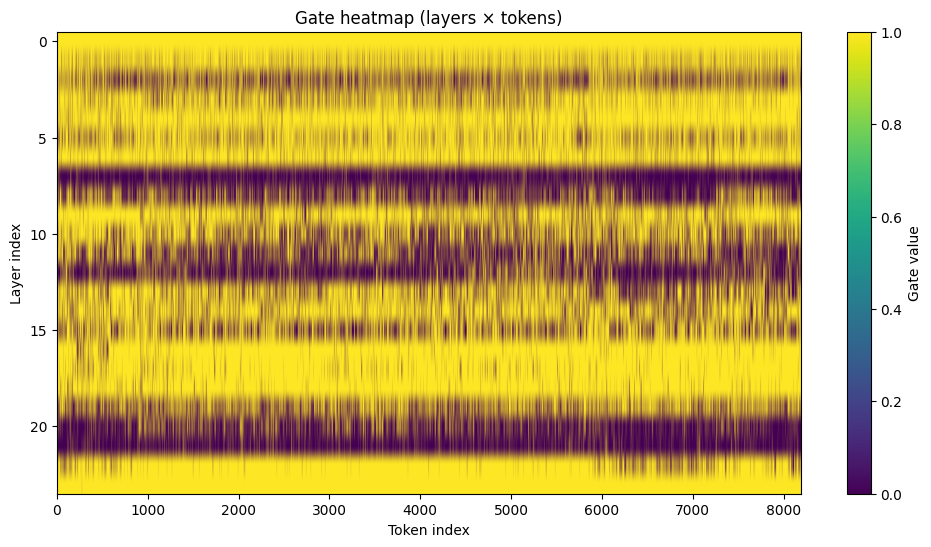

In [43]:
# binary decisions on wiki test data
visualize_gate_heatmap([x.round() for x in gate_store[-24:]])

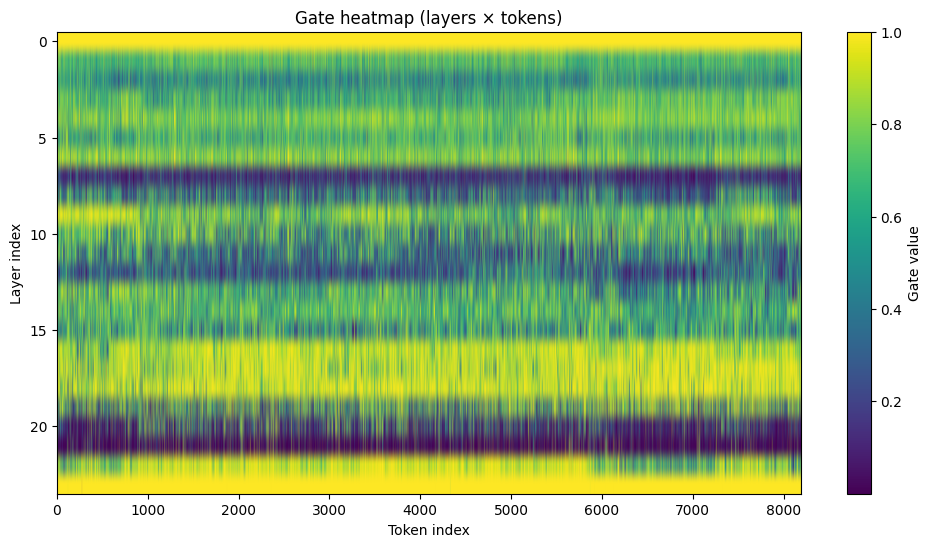

In [44]:
# decisions on wiki test data
visualize_gate_heatmap(gate_store[-24:])

Text(0.5, 1.0, 'Distribution of decisions')

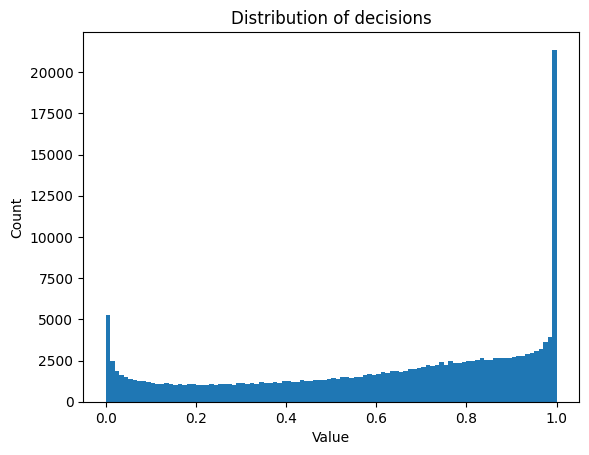

In [45]:
flat = torch.cat([t.reshape(-1) for t in gate_store[-24:]])
values = flat.float().detach().cpu().numpy()
plt.hist(values, bins=100)
plt.xlabel("Value")
plt.ylabel("Count")
plt.title('Distribution of decisions')

## Average weights and bias

<BarContainer object of 24 artists>

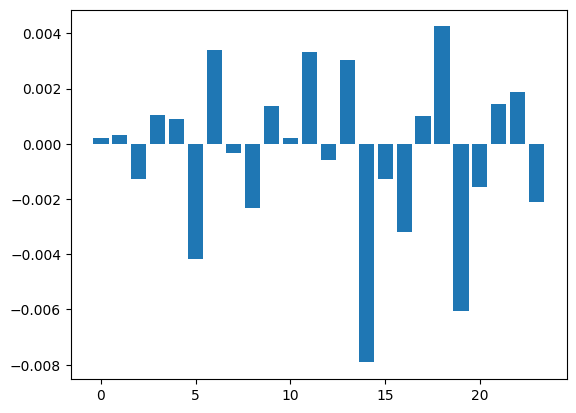

In [46]:
plt.bar(range(24), [model.model.layers[i].mlp.gate.proj.weight.mean().item() for i in range(24)])

<BarContainer object of 24 artists>

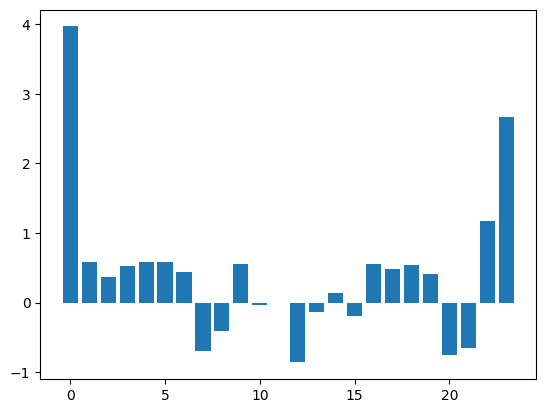

In [47]:
plt.bar(range(24), [model.model.layers[i].mlp.gate.proj.bias.item() for i in range(24)])

# Training with more samples

## 512

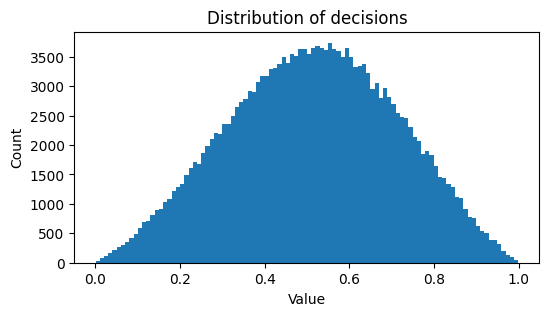

  1 lr 1.0e-02 | ppl=406.17 | val_ppl=  0.00 | skip_ratio=0.48 | skip_ratio_h=0.47 | ratio_loss=0.72 | bin_loss=0.21 | kl_div=4.56 | total_loss=5.49


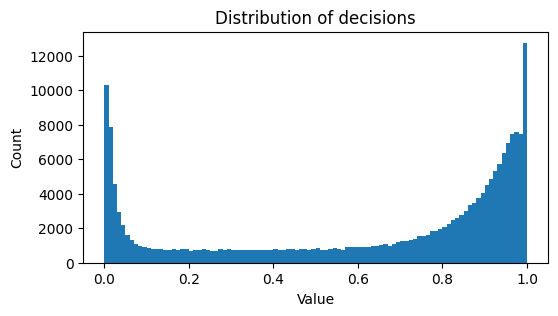

 32 lr 9.4e-03 | ppl=  1.09 | val_ppl=  0.00 | skip_ratio=0.37 | skip_ratio_h=0.33 | ratio_loss=0.11 | bin_loss=0.10 | kl_div=0.51 | total_loss=0.72


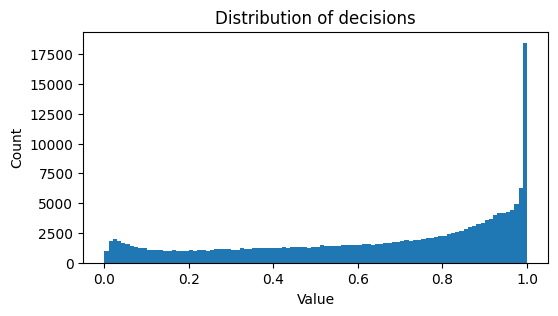

 64 lr 8.8e-03 | ppl=  8.51 | val_ppl=  0.00 | skip_ratio=0.35 | skip_ratio_h=0.31 | ratio_loss=0.25 | bin_loss=0.13 | kl_div=0.62 | total_loss=1.00


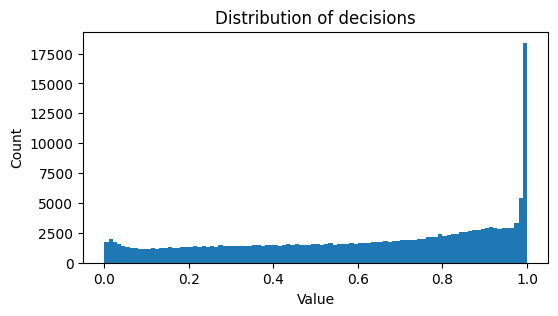

 96 lr 8.1e-03 | ppl=  1.13 | val_ppl=  0.00 | skip_ratio=0.39 | skip_ratio_h=0.36 | ratio_loss=0.02 | bin_loss=0.14 | kl_div=0.54 | total_loss=0.71


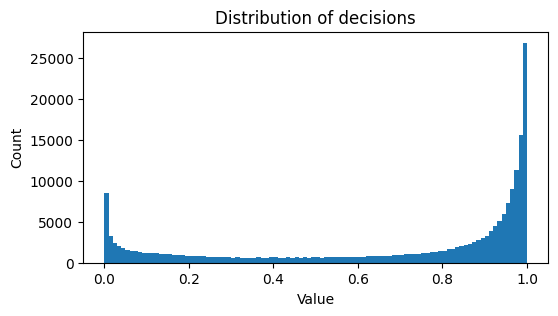

128 lr 7.5e-03 | ppl=  1.01 | val_ppl=  0.00 | skip_ratio=0.31 | skip_ratio_h=0.28 | ratio_loss=0.78 | bin_loss=0.09 | kl_div=0.43 | total_loss=1.29


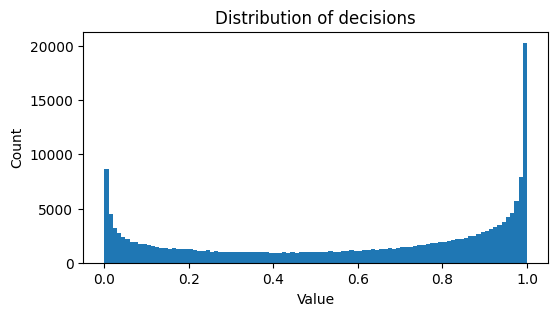

160 lr 6.9e-03 | ppl=  1.14 | val_ppl=  0.00 | skip_ratio=0.41 | skip_ratio_h=0.38 | ratio_loss=0.00 | bin_loss=0.11 | kl_div=0.70 | total_loss=0.82


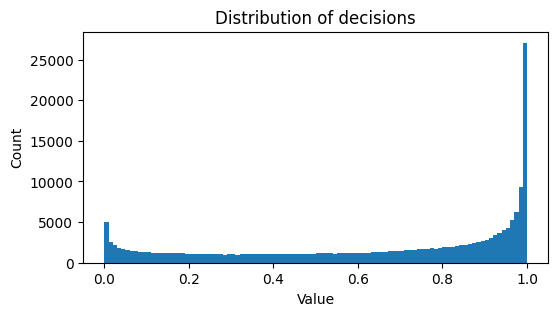

192 lr 6.3e-03 | ppl=  1.01 | val_ppl=  0.00 | skip_ratio=0.35 | skip_ratio_h=0.33 | ratio_loss=0.22 | bin_loss=0.12 | kl_div=0.44 | total_loss=0.77


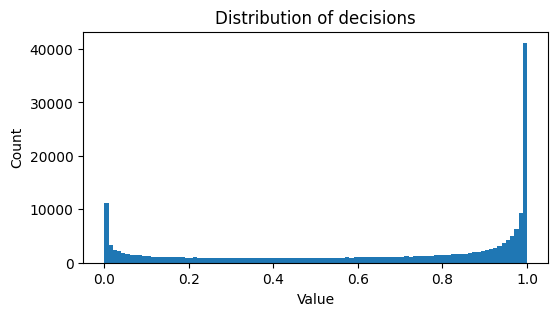

224 lr 5.6e-03 | ppl=  3.44 | val_ppl=  0.00 | skip_ratio=0.35 | skip_ratio_h=0.33 | ratio_loss=0.22 | bin_loss=0.10 | kl_div=0.56 | total_loss=0.88


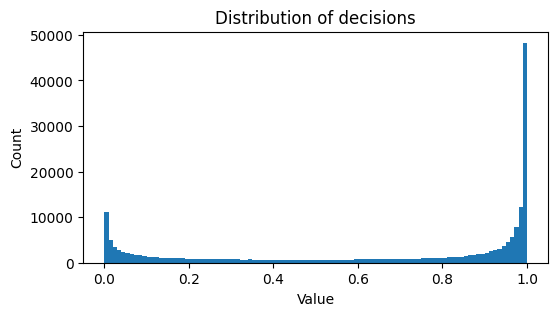

256 lr 5.0e-03 | ppl= 63.73 | val_ppl=  0.00 | skip_ratio=0.34 | skip_ratio_h=0.33 | ratio_loss=0.33 | bin_loss=0.08 | kl_div=0.46 | total_loss=0.86


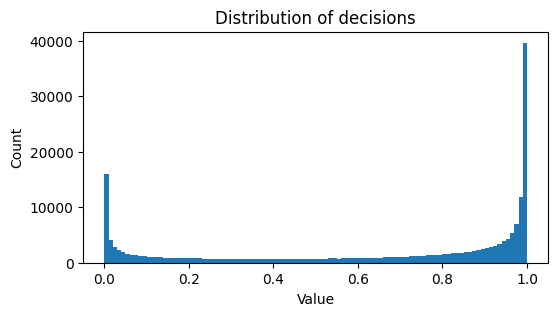

288 lr 4.4e-03 | ppl=  1.30 | val_ppl=  0.00 | skip_ratio=0.35 | skip_ratio_h=0.33 | ratio_loss=0.22 | bin_loss=0.09 | kl_div=0.61 | total_loss=0.91


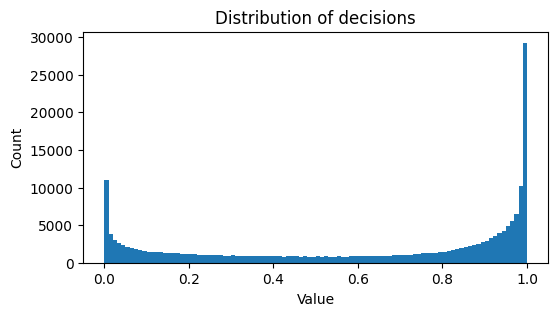

320 lr 3.8e-03 | ppl=452.76 | val_ppl=  0.00 | skip_ratio=0.38 | skip_ratio_h=0.37 | ratio_loss=0.03 | bin_loss=0.10 | kl_div=0.52 | total_loss=0.64


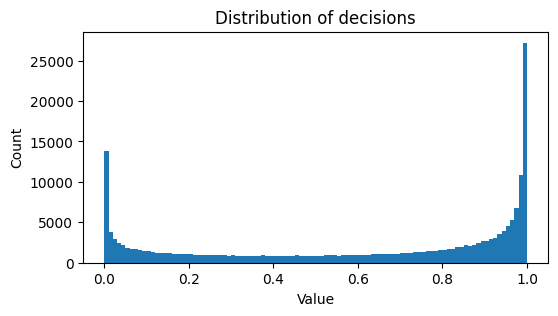

352 lr 3.1e-03 | ppl=  1.83 | val_ppl=  0.00 | skip_ratio=0.39 | skip_ratio_h=0.37 | ratio_loss=0.01 | bin_loss=0.10 | kl_div=0.46 | total_loss=0.58


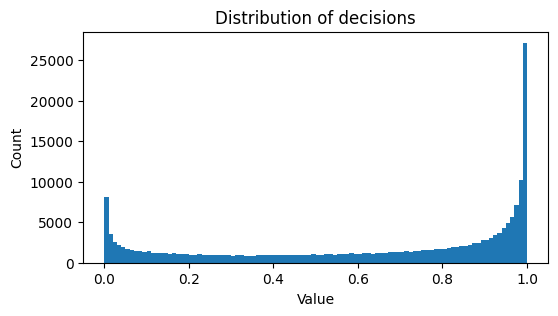

384 lr 2.5e-03 | ppl=  3.41 | val_ppl=  0.00 | skip_ratio=0.36 | skip_ratio_h=0.33 | ratio_loss=0.16 | bin_loss=0.11 | kl_div=0.42 | total_loss=0.69


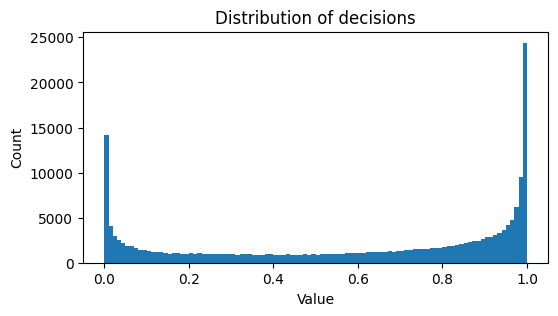

416 lr 1.9e-03 | ppl=  1.13 | val_ppl=  0.00 | skip_ratio=0.40 | skip_ratio_h=0.37 | ratio_loss=0.00 | bin_loss=0.11 | kl_div=0.33 | total_loss=0.44


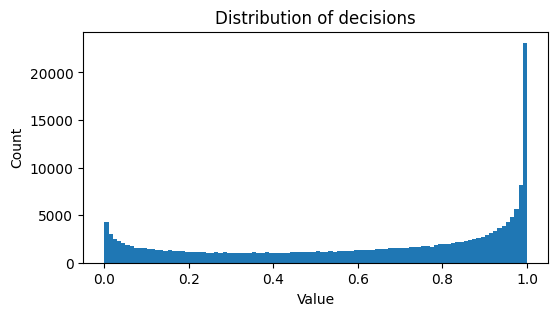

448 lr 1.3e-03 | ppl=  1.93 | val_ppl=  0.00 | skip_ratio=0.37 | skip_ratio_h=0.34 | ratio_loss=0.08 | bin_loss=0.12 | kl_div=0.35 | total_loss=0.55


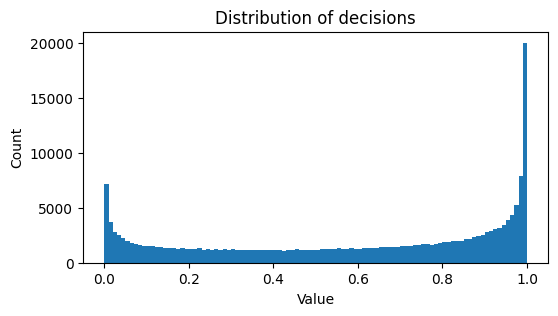

480 lr 6.3e-04 | ppl= 37.04 | val_ppl=  0.00 | skip_ratio=0.41 | skip_ratio_h=0.39 | ratio_loss=0.01 | bin_loss=0.12 | kl_div=0.52 | total_loss=0.65


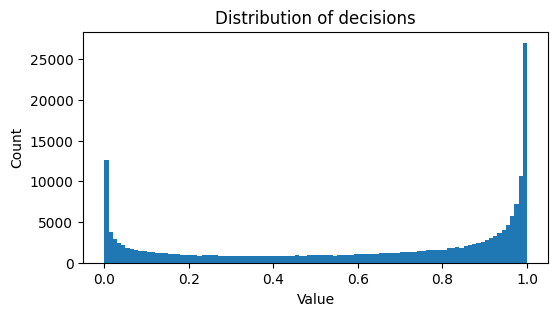

512 lr 1.0e-05 | ppl=  1.01 | val_ppl=  0.00 | skip_ratio=0.38 | skip_ratio_h=0.35 | ratio_loss=0.05 | bin_loss=0.10 | kl_div=0.31 | total_loss=0.46


In [18]:
stats = {'ppl': [], 'val_ppl': [], 'kl_div': [], 'skip_ratio': [], 'ratio_loss': [], 'bin_loss': [], 'total_loss': []}

model = get_opt(model_name)
gate_store = []
add_gates(model, gate_store=gate_store)
model.to(DEV)
model.train()

set_init_gate_weights(model, init_skip=0.5, w_std=1e-1)
freeze_all_but_gates(model)

model, stats = train_gates(
    model=model,
    dataloader=dataloader,
    gate_store=gate_store,
    stats=stats,
    device=DEV,
    epochs=1,
    lrb=1, lrw=1e-2,
    sigma_max=0.5, sigma_limit=0.7, tau_min=0.4, tau_limit=0.5,
    target_skip=0.40,
    lambda_ratio=1e2,
    lambda_bin=1,
    grad_accum_steps=1,
    log_every=32,
    verbose=True,
    eval_val_ppl=False
)
# model.eval();

In [19]:
gate_store.clear()
model.eval()
eval_ppl(model, wiki_testloader, device=DEV)

16.030500411987305

In [20]:
# skip ratio
# torch.Tensor([x.mean() for x in gate_store]).mean()
1-torch.Tensor([x.mean() for x in gate_store[-24:]]).mean().item(), 1-torch.Tensor([x.round().mean() for x in gate_store[-24:]]).mean().item()

(0.37942713499069214, 0.3469899296760559)

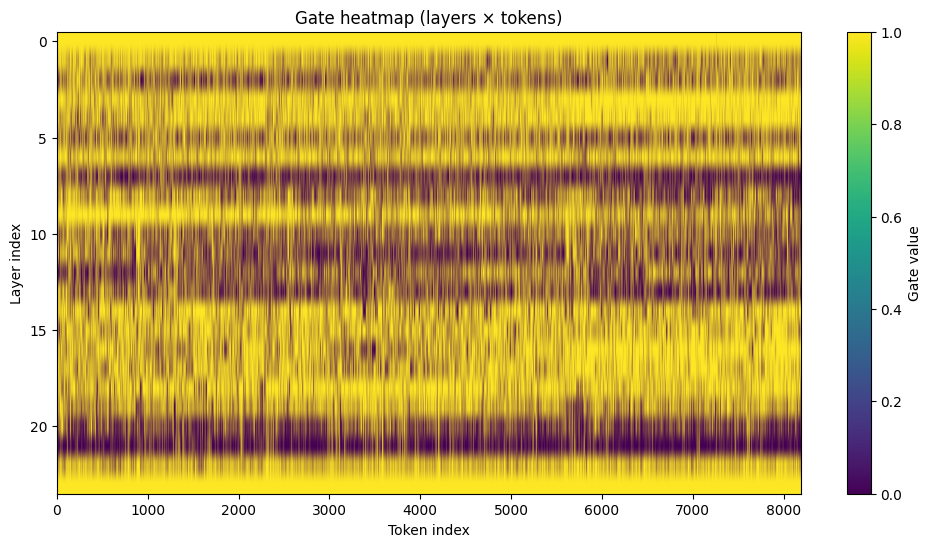

In [21]:
# binary decisions on wiki test data
visualize_gate_heatmap([x.round() for x in gate_store[-24:]])

# Hyperparameter search

In [15]:
def train_and_eval(lrb, lrw, init_skip, target_skip):
    stats = {'ppl': [], 'val_ppl': [], 'kl_div': [], 'skip_ratio': [], 'ratio_loss': [], 'bin_loss': [], 'total_loss': []}

    model = get_opt(model_name)
    gate_store = []
    add_gates(model, gate_store=gate_store)
    model.to(DEV)
    model.train()
    
    set_init_gate_weights(model, init_skip=init_skip, w_std=1e-1)
    freeze_all_but_gates(model)
    
    model, stats = train_gates(
        model=model,
        dataloader=dataloader,
        gate_store=gate_store,
        stats=stats,
        device=DEV,
        epochs=1,
        lrw=lrw, lrb=lrb,
        sigma_max=0.5, sigma_limit=0.7, tau_min=0.4, tau_limit=0.5,
        target_skip=target_skip,
        lambda_ratio=1e2,
        lambda_bin=1,
        grad_accum_steps=1,
        log_every=8,
        verbose=False,
        eval_val_ppl=False
    )
    
    gate_store.clear()
    model.eval()
    val_ppl = eval_ppl(model, wiki_testloader, device=DEV)
    skip_ratio_bin = 1-torch.Tensor([x.round().mean() for x in gate_store[-24:]]).mean().item()
    return val_ppl, skip_ratio_bin


In [16]:
results_df = pd.read_csv('results/kl_gate_training_512.csv')

In [24]:
dataloader = dataloader[:256]

In [25]:
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

n_samples = 256
results = []

for init_skip in (0.3, 0.5):
    for target_skip in (0.3, 0.4, 0.5):
        for lrb in (10, 1, 1e-1):
            for lrw in (1e-1, 1e-2, 1e-3, 1e-4):
                print(f"init_skip={init_skip}, target_skip={target_skip}, lrb={lrb}, lrw={lrw}")
                for run_i in range(2):
                    val_ppl, skip_ratio = train_and_eval(lrb=lrb, lrw=lrw, init_skip=init_skip, target_skip=target_skip)
                    results.append([n_samples, init_skip, target_skip, lrb, lrw, run_i, val_ppl, skip_ratio])
                    # results_df.loc[len(results_df)] = [n_samples, init_skip, target_skip, lrb, lrw, run_i, val_ppl, skip_ratio]
                    results_df = pd.DataFrame(results, columns=['n_samples', 'init_skip', 'target_skip', 'lrb', 'lrw', 'run_i', 'val_ppl', 'skip_ratio'])
                    results_df.to_csv('results/kl_gate_training_256.csv', index=False)
                    print(f"val_ppl={val_ppl:.2f} skip_ratio={skip_ratio:.2f}")
                print()


init_skip=0.3, target_skip=0.3, lrb=10, lrw=0.1
val_ppl=16.02 skip_ratio=0.28
val_ppl=17.82 skip_ratio=0.29

init_skip=0.3, target_skip=0.3, lrb=10, lrw=0.01
val_ppl=15.05 skip_ratio=0.28
val_ppl=19.90 skip_ratio=0.27

init_skip=0.3, target_skip=0.3, lrb=10, lrw=0.001
val_ppl=16.84 skip_ratio=0.27
val_ppl=78.11 skip_ratio=0.25

init_skip=0.3, target_skip=0.3, lrb=10, lrw=0.0001
val_ppl=223.45 skip_ratio=0.28
val_ppl=18.63 skip_ratio=0.29

init_skip=0.3, target_skip=0.3, lrb=1, lrw=0.1
val_ppl=12.17 skip_ratio=0.27
val_ppl=12.32 skip_ratio=0.26

init_skip=0.3, target_skip=0.3, lrb=1, lrw=0.01
val_ppl=11.14 skip_ratio=0.26
val_ppl=12.24 skip_ratio=0.28

init_skip=0.3, target_skip=0.3, lrb=1, lrw=0.001
val_ppl=12.05 skip_ratio=0.21
val_ppl=14.79 skip_ratio=0.23

init_skip=0.3, target_skip=0.3, lrb=1, lrw=0.0001
val_ppl=40.94 skip_ratio=0.23
val_ppl=48.74 skip_ratio=0.25

init_skip=0.3, target_skip=0.3, lrb=0.1, lrw=0.1
val_ppl=12.94 skip_ratio=0.27
val_ppl=12.89 skip_ratio=0.27

init_skip

In [16]:
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

n_samples = 512
run_i = 0
results = []

for init_skip in (0.5,):
    for target_skip in (0.5,):
        for lrb in (10, 1, 1e-1):
            for lrw in (1e-1, 1e-2, 1e-3):
                print(f"init_skip={init_skip}, target_skip={target_skip}, lrb={lrb}, lrw={lrw}")
                # for run_i in range(2):
                val_ppl, skip_ratio = train_and_eval(lrb=lrb, lrw=lrw, init_skip=init_skip, target_skip=target_skip)
                results.append([n_samples, init_skip, target_skip, lrb, lrw, run_i, val_ppl, skip_ratio])
                # results_df.loc[len(results_df)] = [n_samples, init_skip, target_skip, lrb, lrw, run_i, val_ppl, skip_ratio]
                results_df = pd.DataFrame(results, columns=['n_samples', 'init_skip', 'target_skip', 'lrb', 'lrw', 'run_i', 'val_ppl', 'skip_ratio'])
                results_df.to_csv('results/kl_gate_training_512b.csv', index=False)
                print(f"val_ppl={val_ppl:.2f} skip_ratio={skip_ratio:.2f}")
                print()


init_skip=0.5, target_skip=0.5, lrb=10, lrw=0.1
val_ppl=43.36 skip_ratio=0.44

init_skip=0.5, target_skip=0.5, lrb=10, lrw=0.01
val_ppl=46.76 skip_ratio=0.45

init_skip=0.5, target_skip=0.5, lrb=10, lrw=0.001
val_ppl=118.25 skip_ratio=0.42

init_skip=0.5, target_skip=0.5, lrb=1, lrw=0.1
val_ppl=38.46 skip_ratio=0.46

init_skip=0.5, target_skip=0.5, lrb=1, lrw=0.01
val_ppl=30.65 skip_ratio=0.44

init_skip=0.5, target_skip=0.5, lrb=1, lrw=0.001
val_ppl=38.55 skip_ratio=0.42

init_skip=0.5, target_skip=0.5, lrb=0.1, lrw=0.1
val_ppl=41.84 skip_ratio=0.46

init_skip=0.5, target_skip=0.5, lrb=0.1, lrw=0.01
val_ppl=38.29 skip_ratio=0.44

init_skip=0.5, target_skip=0.5, lrb=0.1, lrw=0.001
val_ppl=55.20 skip_ratio=0.44



## Result visualization

In [17]:
gate_results = pd.read_csv('results/kl_gate_training.csv')
block_pruner = pd.read_csv('results/results_block_pruner.csv', index_col=0)
block_pruner['del_ratio'] = block_pruner.index / 24

In [18]:
gate_results.loc[(gate_results['skip_ratio'] > 0.25) & (gate_results['val_ppl'] < 60)].sort_values(by='val_ppl')

,n_samples,lrb,lrw,run_i,val_ppl,skip_ratio,init_skip,target_skip
322,512.0,1.0,1.000000e-02,0.0,10.662846,0.252162,0.3,0.3
376,512.0,1.0,1.000000e-02,1.0,10.899587,0.256897,0.5,0.3
324,512.0,1.0,1.000000e-02,2.0,10.913402,0.251714,0.3,0.3
323,512.0,1.0,1.000000e-02,1.0,11.036218,0.256231,0.3,0.3
383,512.0,0.1,1.000000e-02,0.0,11.085263,0.255686,0.5,0.3
...,...,...,...,...,...,...,...,...
421,512.0,0.1,1.000000e-03,0.0,55.200920,0.437129,0.5,0.5
18,128.0,10.0,1.000000e-08,0.0,55.575165,0.291743,0.3,0.3
184,256.0,10.0,1.000000e-04,0.0,55.692631,0.345398,0.3,0.4
140,128.0,1.0,1.000000e-02,1.0,57.752445,0.447881,0.3,0.5


In [26]:
gate_results_best = gate_results.loc[
    gate_results['lrb'].isin([10, 1, 0.1])
    & gate_results['lrw'].isin([1e-1, 1e-2, 1e-3])
]

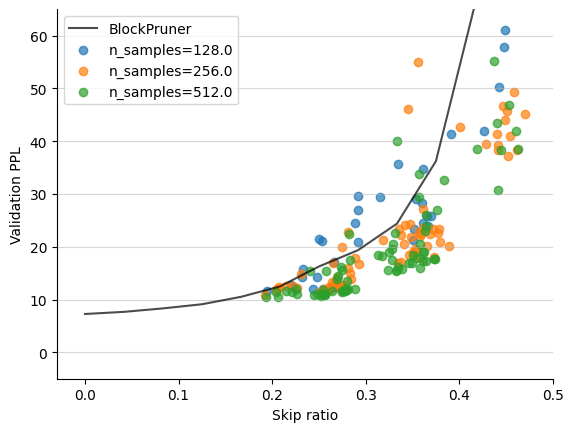

In [27]:
results_df = gate_results_best
param = "n_samples"
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', alpha=0.7, label='BlockPruner')
for x, group in results_df.groupby(param):
    plt.scatter(group["skip_ratio"], group["val_ppl"], alpha=0.7,
                label=f"{param}={x}")
plt.xlim((-0.03, 0.5))
plt.ylim((-5, 65))
plt.grid(axis='y', alpha=0.5)
plt.xlabel("Skip ratio")
plt.ylabel("Validation PPL")
plt.legend(title=param)
plt.legend(loc="upper left")
sns.despine()
plt.show()